In [1]:
import pandas as pd
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/dataset.csv")

In [2]:
print(df.head())


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   

   split  
0  train  
1  train  
2  train  
3  train  
4  train  


In [3]:
print(df.shape)

(2200, 4)


In [4]:
print("\n=== Columns ===")
print(df.columns)

print("\n=== Intent distribution ===")
print(df['intent'].value_counts())

print("\n=== Split distribution ===")
print(df['split'].value_counts())

print("\n=== Sample examples ===")
print(df.sample(5))


=== Columns ===
Index(['id', 'text', 'intent', 'split'], dtype='object')

=== Intent distribution ===
intent
plan_itinerary         200
recommend_pois         200
modify_itinerary       200
crowd_forecast         200
info_attraction        200
info_accommodation     200
info_transport         200
info_visa_policy       200
update_preferences     200
explanation_request    200
generic_fact_query     200
Name: count, dtype: int64

=== Split distribution ===
split
train    1760
val       220
test      220
Name: count, dtype: int64

=== Sample examples ===
        id                                               text  \
916    917             Is Colombo suitable for solo traveler?   
1974  1975       Why did you choose Sigiriya in my itinerary?   
1408  1409  How long can I stay in Sri Lanka on a tourist ...   
721    722        How crowded is Mirissa usually in December?   
2139  2140              How is the weather in Galle in April?   

                   intent  split  
916       info

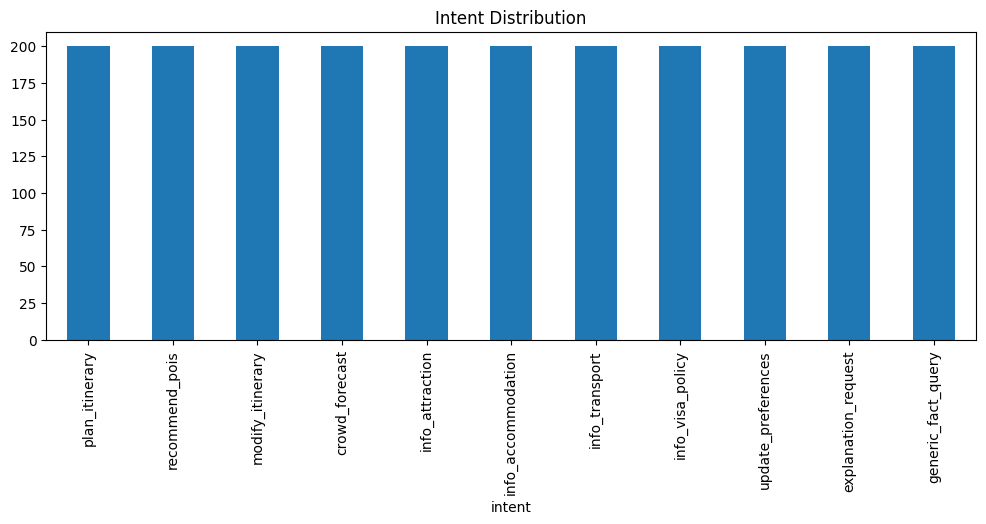

In [5]:
import matplotlib.pyplot as plt

df['intent'].value_counts().plot(kind='bar', figsize=(12,4))
plt.title("Intent Distribution")
plt.show()


In [6]:
dup_texts = df['text'][df['text'].duplicated()].unique()



In [7]:
df_duplicates = df[df['text'].isin(dup_texts)]
df_duplicates


,id,text,intent,split
3,4,I need a 4-day eco friendly itinerary in Nuwar...,plan_itinerary,train
11,12,I need a 6-day eco friendly itinerary in Galle...,plan_itinerary,train
12,13,I need a 5-day eco friendly itinerary in Kandy...,plan_itinerary,train
14,15,I need a 5-day eco friendly itinerary in Colom...,plan_itinerary,train
27,28,I need a 3-day eco friendly itinerary in Nuwar...,plan_itinerary,train
...,...,...,...,...
2193,2194,How is the weather in Galle in August?,generic_fact_query,test
2195,2196,What local customs should I know in Sri Lanka?,generic_fact_query,test
2196,2197,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test
2198,2199,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test


In [8]:
print("Before:", len(df))

df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

print("After :", len(df_no_exact_dups))
print("Removed exact duplicates:", len(df) - len(df_no_exact_dups))


Before: 2200
After : 801
Removed exact duplicates: 1399


In [9]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']
print(intent_counts)


                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [10]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']

# Save to CSV
intent_counts.to_csv("Without_duplicates.csv", index=False)

print("Without_duplicates.csv")
print(intent_counts)


Without_duplicates.csv
                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [11]:
# After running:
# df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

# Save cleaned dataset to CSV
df_no_exact_dups.to_csv("dataset_no_dups.csv", index=False)

print("dataset_no_dups.csv")


dataset_no_dups.csv


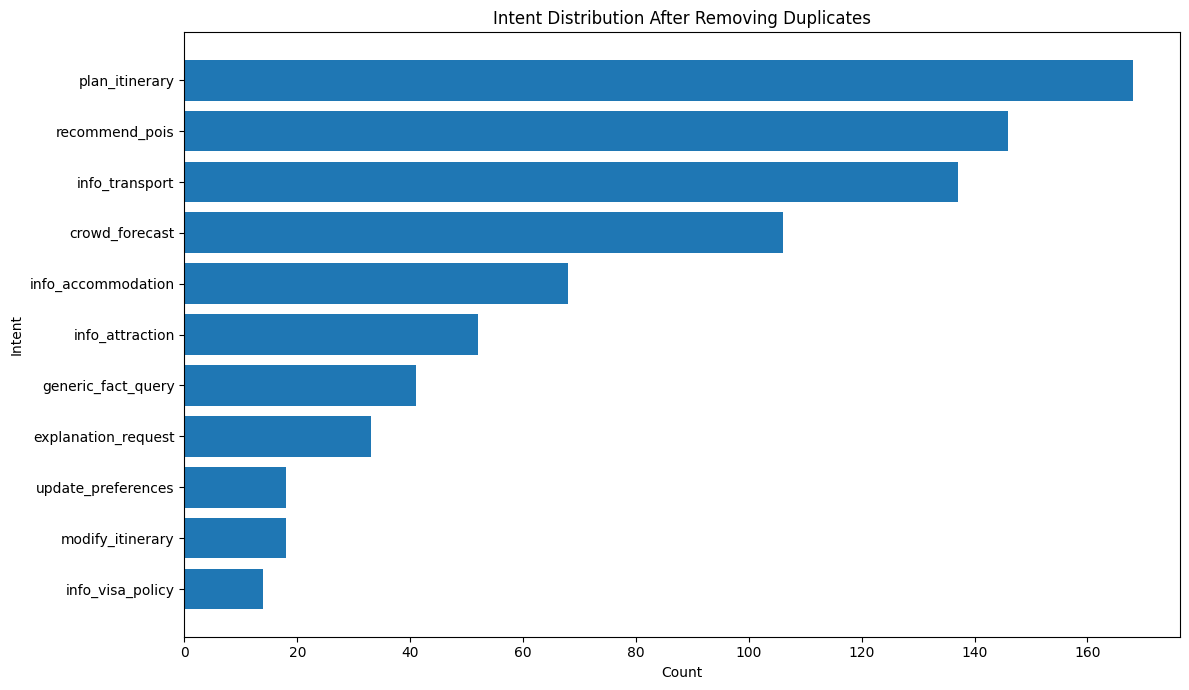

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load full dataset (after removing duplicates)
df = pd.read_csv("dataset_no_dups.csv")

# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()



In [13]:
df[df.duplicated('text', keep=False)]


,id,text,intent,split


In [14]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/datasetV1.csv")
len(df)



871

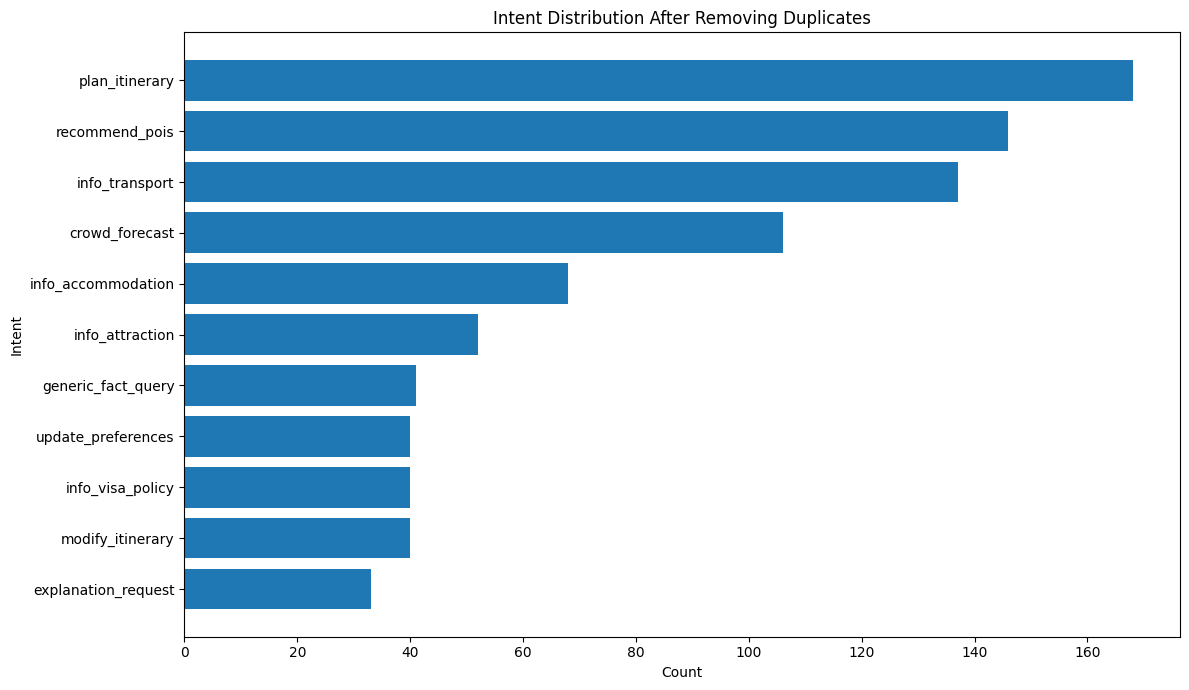

In [15]:
# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()

In [16]:
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/datasetV1.csv")

# Count rows per intent
intent_counts = df['intent'].value_counts()

print(intent_counts)

intent
plan_itinerary         168
recommend_pois         146
info_transport         137
crowd_forecast         106
info_accommodation      68
info_attraction         52
generic_fact_query      41
modify_itinerary        40
info_visa_policy        40
update_preferences      40
explanation_request     33
Name: count, dtype: int64


In [17]:
import pandas as pd

# Load your multi-label dataset
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

# If num_labels column does not exist, compute it
if "num_labels" not in df.columns:
    df["num_labels"] = df["labels"].apply(lambda s: len(str(s).split(";")))

print("=== Label Count Distribution ===")
print(df["num_labels"].value_counts().sort_index())

print("\n=== Percentage Distribution ===")
print((df["num_labels"].value_counts(normalize=True).sort_index() * 100).round(2))

# Optional: show examples with exactly 2 labels
print("\n=== Sample examples with exactly 2 labels ===")
print(df[df["num_labels"] == 2][["text", "labels"]].head(10))


=== Label Count Distribution ===
num_labels
1    1039
2     202
3      16
4       1
Name: count, dtype: int64

=== Percentage Distribution ===
num_labels
1    82.59
2    16.06
3     1.27
4     0.08
Name: proportion, dtype: float64

=== Sample examples with exactly 2 labels ===
                                                  text  \
168  Give me a few budget attractions close to Nuwa...   
175  What are some romantic things to do near Colombo?   
176  Give me a few nature attractions close to Mirissa   
177  What are some quiet things to do near Nuwara E...   
181  What are some eco friendly things to do near S...   
182  Give me a few photography attractions close to...   
183  Give me a few family friendly attractions clos...   
184  What are some nature things to do near Trincom...   
185  What are some budget things to do near Trincom...   
189     Give me a few nature attractions close to Ella   

                             labels  
168  info_attraction;recommend_pois  
175  in

In [18]:
df[df["text"].str.contains("hotel", case=False)][["text", "labels"]].head(20)


,text,labels
492,Suggest luxury hotels in Trincomalee for a couple,info_accommodation
494,Suggest mid range hotels in Kandy for elderly ...,info_accommodation
495,What is the average price per night for a hote...,info_accommodation
496,What is the average price per night for a hote...,info_accommodation
497,Suggest luxury hotels in Mirissa for elderly p...,info_accommodation
499,Suggest strict hotels in Sigiriya for a family,info_accommodation
501,What is the average price per night for a hote...,info_accommodation
502,What is the average price per night for a hote...,info_accommodation
506,Suggest mid range hotels in Sigiriya for solo ...,info_accommodation
507,What is the average price per night for a hote...,info_accommodation


In [19]:
df[df["text"].str.contains("crowd|busy|packed|quiet", case=False)][["text", "labels"]].head(20)


,text,labels
172,Suggest quiet places near Nuwara Eliya for one...,recommend_pois
177,What are some quiet things to do near Nuwara E...,info_attraction;recommend_pois
216,Recommend some quiet spots around Ella for eld...,recommend_pois
225,What are some quiet things to do near Ella?,info_attraction;recommend_pois
237,Suggest quiet places near Mirissa for one day,recommend_pois
238,Suggest quiet places near Colombo for one day,recommend_pois
248,Suggest quiet places near Galle for one day,recommend_pois
256,Suggest quiet places near Kandy for one day,recommend_pois
257,Give me a few quiet attractions close to Nuwar...,info_attraction;recommend_pois
258,Recommend some quiet spots around Colombo for ...,recommend_pois


In [20]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

co_occurrence = {}

for labels in df["labels"]:
    labs = labels.split(";")
    for l1 in labs:
        for l2 in labs:
            if l1 == l2:
                continue
            co_occurrence[(l1, l2)] = co_occurrence.get((l1, l2), 0) + 1

# Sort by frequency
sorted_pairs = sorted(co_occurrence.items(), key=lambda x: x[1], reverse=True)

# Show top 20 co-occurrences
for pair, count in sorted_pairs[:20]:
    print(pair, count)


('info_attraction', 'recommend_pois') 65
('recommend_pois', 'info_attraction') 65
('info_accommodation', 'info_visa_policy') 29
('info_visa_policy', 'info_accommodation') 29
('crowd_forecast', 'forecast_weather') 20
('forecast_weather', 'crowd_forecast') 20
('forecast_sustainability', 'forecast_weather') 16
('forecast_weather', 'forecast_sustainability') 16
('forecast_price', 'forecast_weather') 14
('forecast_weather', 'forecast_price') 14
('crowd_forecast', 'update_preferences') 9
('update_preferences', 'crowd_forecast') 9
('crowd_forecast', 'explanation_request') 8
('explanation_request', 'crowd_forecast') 8
('explanation_request', 'info_accommodation') 8
('info_accommodation', 'explanation_request') 8
('info_transport', 'modify_itinerary') 6
('modify_itinerary', 'info_transport') 6
('crowd_forecast', 'modify_itinerary') 6
('modify_itinerary', 'crowd_forecast') 6


In [21]:
df.shape

(1258, 6)

In [22]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, classification_report, accuracy_score

from datasets import Dataset, DatasetDict

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
import torch


ModuleNotFoundError: No module named 'datasets'

In [ ]:
# Path to your multi-label dataset
CSV_PATH = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv"

df = pd.read_csv(CSV_PATH)
print(df.head())
print(df.columns)
print(df.shape)


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   

   split          labels  num_labels  
0  train  plan_itinerary           1  
1  train  plan_itinerary           1  
2  train  plan_itinerary           1  
3  train  plan_itinerary           1  
4  train  plan_itinerary           1  
Index(['id', 'text', 'intent', 'split', 'labels', 'num_labels'], dtype='object')
(1218, 6)


In [ ]:
INTENT_LABELS = [
    "plan_itinerary",
    "recommend_pois",
    "modify_itinerary",

    # Forecasting-related intents (NEW)
    "crowd_forecast",
    "forecast_weather",
    "forecast_price",
    "forecast_sustainability",

    # Information-based intents
    "info_attraction",
    "info_accommodation",
    "info_transport",
    "info_visa_policy",

    # Preference & meta intents
    "update_preferences",
    "explanation_request",

    # General fallback
    "generic_fact_query"
]


num_labels = len(INTENT_LABELS)
label2id = {lbl: i for i, lbl in enumerate(INTENT_LABELS)}
id2label = {i: lbl for lbl, i in label2id.items()}

label2id, id2label


({'plan_itinerary': 0,
  'recommend_pois': 1,
  'modify_itinerary': 2,
  'crowd_forecast': 3,
  'forecast_weather': 4,
  'forecast_price': 5,
  'forecast_sustainability': 6,
  'info_attraction': 7,
  'info_accommodation': 8,
  'info_transport': 9,
  'info_visa_policy': 10,
  'update_preferences': 11,
  'explanation_request': 12,
  'generic_fact_query': 13},
 {0: 'plan_itinerary',
  1: 'recommend_pois',
  2: 'modify_itinerary',
  3: 'crowd_forecast',
  4: 'forecast_weather',
  5: 'forecast_price',
  6: 'forecast_sustainability',
  7: 'info_attraction',
  8: 'info_accommodation',
  9: 'info_transport',
  10: 'info_visa_policy',
  11: 'update_preferences',
  12: 'explanation_request',
  13: 'generic_fact_query'})

In [ ]:
# Parse "labels" column: "plan_itinerary;info_accommodation" → ["plan_itinerary", "info_accommodation"]
def parse_labels(label_str):
    if pd.isna(label_str):
        return []
    return [x.strip() for x in str(label_str).split(";") if x.strip()]

df["label_list"] = df["labels"].apply(parse_labels)

# Use MultiLabelBinarizer to get multi-hot vectors
mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
Y = mlb.fit_transform(df["label_list"])

print("Multi-hot shape:", Y.shape)
print("Example row:", df["text"].iloc[0], "→", df["label_list"].iloc[0], "→", Y[0])


Multi-hot shape: (1218, 14)
Example row: Plan a 2-day trip to Nuwara Eliya for a family with a low budget → ['plan_itinerary'] → [1 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

# Make sure label_list exists
df["label_list"] = df["labels"].apply(parse_labels)

# If you still have an old 'split' column, drop it so it doesn't confuse anything
if "split" in df.columns:
    df = df.drop(columns=["split"])

# Stratify by primary intent (single label column)
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["intent"]   # keeps primary intent balance
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["intent"]
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# Now build Y from these splits
Y_train = mlb.transform(train_df["label_list"])
Y_val   = mlb.transform(val_df["label_list"])
Y_test  = mlb.transform(test_df["label_list"])

print("Train:", Y_train.shape, "Val:", Y_val.shape, "Test:", Y_test.shape)


Train: (974, 14) Val: (122, 14) Test: (122, 14)


In [ ]:
# Attach the multi-hot label vectors as a column
train_df = train_df.copy()
val_df   = val_df.copy()
test_df  = test_df.copy()

train_df["labels_vec"] = list(Y_train)
val_df["labels_vec"]   = list(Y_val)
test_df["labels_vec"]  = list(Y_test)

# Keep only necessary columns for training
train_df_small = train_df[["text", "labels_vec"]]
val_df_small   = val_df[["text", "labels_vec"]]
test_df_small  = test_df[["text", "labels_vec"]]

train_ds = Dataset.from_pandas(train_df_small)
val_ds   = Dataset.from_pandas(val_df_small)
test_ds  = Dataset.from_pandas(test_df_small)

dataset = DatasetDict({
    "train": train_ds,
    "validation": val_ds,
    "test": test_ds,
})

dataset


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 974
    })
    validation: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 122
    })
    test: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 122
    })
})

In [ ]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    # Tokenize the text
    encodings = tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )
    # Attach labels
    encodings["labels"] = examples["labels_vec"]
    return encodings

encoded_dataset = dataset.map(preprocess_function, batched=True)
encoded_dataset




Map: 100%|██████████| 122/122 [00:00<00:00, 16946.68 examples/s]


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 974
    })
    validation: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 122
    })
    test: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 122
    })
})

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification",
    id2label=id2label,
    label2id=label2id,
)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
from scipy.special import expit  # sigmoid

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Apply sigmoid to get probabilities
    probs = expit(logits)
    
    # Choose threshold
    threshold = 0.5
    preds = (probs >= threshold).astype(int)

    # Micro-F1 (overall)
    micro_f1 = f1_score(labels, preds, average="micro", zero_division=0)
    # Macro-F1 (per-label average)
    macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)

    # Subset accuracy: exact match of all labels
    subset_acc = accuracy_score(labels, preds)

    metrics = {
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "subset_accuracy": subset_acc,
    }
    return metrics


In [ ]:
def preprocess_function(examples):
    # Tokenize text
    encodings = tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )
    
    # Convert labels_vec → float32
    # examples["labels_vec"] is a list of lists / arrays like [[0,1,0,...], [1,0,0,...], ...]
    labels = examples["labels_vec"]
    encodings["labels"] = [[float(x) for x in row] for row in labels]
    
    return encodings


In [ ]:
encoded_dataset = dataset.map(preprocess_function, batched=True)


Map: 100%|██████████| 122/122 [00:00<00:00, 23940.54 examples/s]


In [ ]:
batch_size = 8  # or 4 if needed

training_args = TrainingArguments(
    output_dir="distilbert-multilabel-intent",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=8,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=20,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()


/var/folders/1p/qlf5xb2x4ssb37hfn51_pfxm0000gn/T/ipykernel_78810/3562722207.py:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Subset Accuracy
1,0.280500,0.258941,0.000000,0.000000,0.000000
2,0.175600,0.159838,0.672897,0.386567,0.500000
3,0.115500,0.103074,0.831276,0.614957,0.704918
4,0.084200,0.073946,0.928839,0.874494,0.860656
5,0.061300,0.057885,0.960000,0.944551,0.909836
6,0.052700,0.049796,0.971223,0.964129,0.934426
7,0.045100,0.045781,0.967509,0.951374,0.926230
8,0.047100,0.044331,0.963768,0.947197,0.918033


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supp

TrainOutput(global_step=976, training_loss=0.13122022884791015, metrics={'train_runtime': 149.5395, 'train_samples_per_second': 52.107, 'train_steps_per_second': 6.527, 'total_flos': 258101715296256.0, 'train_loss': 0.13122022884791015, 'epoch': 8.0})

In [ ]:
from pathlib import Path

SAVE_DIR = Path("/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final")

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)


('/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/tokenizer_config.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/special_tokens_map.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/vocab.txt',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/added_tokens.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/tokenizer.json')

In [ ]:
test_metrics = trainer.evaluate(encoded_dataset["test"])
test_metrics


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


{'eval_loss': 0.05261092260479927,
 'eval_micro_f1': 0.9530685920577617,
 'eval_macro_f1': 0.9437192965764395,
 'eval_subset_accuracy': 0.8934426229508197,
 'eval_runtime': 0.6804,
 'eval_samples_per_second': 179.297,
 'eval_steps_per_second': 23.514,
 'epoch': 8.0}

In [ ]:
# Get raw predictions on test set
raw_preds = trainer.predict(encoded_dataset["test"])
logits = raw_preds.predictions
labels_true = raw_preds.label_ids

probs = expit(logits)
threshold = 0.5
preds = (probs >= threshold).astype(int)

print("Micro F1:", f1_score(labels_true, preds, average="micro", zero_division=0))
print("Macro F1:", f1_score(labels_true, preds, average="macro", zero_division=0))

# Per-label F1
for i, label_name in id2label.items():
    f1 = f1_score(labels_true[:, i], preds[:, i], average="binary", zero_division=0)
    support = labels_true[:, i].sum()
    print(f"{label_name:20s} F1 = {f1:.3f} (support={support})")


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)


Micro F1: 0.9530685920577617
Macro F1: 0.9437192965764395
plan_itinerary       F1 = 1.000 (support=17.0)
recommend_pois       F1 = 1.000 (support=16.0)
modify_itinerary     F1 = 1.000 (support=5.0)
crowd_forecast       F1 = 0.960 (support=13.0)
forecast_weather     F1 = 0.923 (support=14.0)
forecast_price       F1 = 0.889 (support=5.0)
forecast_sustainability F1 = 1.000 (support=9.0)
info_attraction      F1 = 0.929 (support=15.0)
info_accommodation   F1 = 0.909 (support=12.0)
info_transport       F1 = 0.933 (support=15.0)
info_visa_policy     F1 = 0.923 (support=7.0)
update_preferences   F1 = 1.000 (support=7.0)
explanation_request  F1 = 0.857 (support=4.0)
generic_fact_query   F1 = 0.889 (support=5.0)


In [ ]:
from scipy.special import expit
import numpy as np
import torch

def predict_intents_safe(text, threshold=0.2, top_k_if_empty=2):
    model.eval()
    
    device = next(model.parameters()).device

    with torch.no_grad():
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            padding=True,
            max_length=128,
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        outputs = model(**inputs)
        logits = outputs.logits.detach().cpu().numpy()
        probs = expit(logits)[0]

    # First pass: strict threshold
    pred_indices = np.where(probs >= threshold)[0]

    # If nothing passes threshold, pick the top-k labels instead
    if len(pred_indices) == 0 and top_k_if_empty is not None:
        top_indices = probs.argsort()[-top_k_if_empty:][::-1]
        pred_indices = top_indices

    pred_labels = [id2label[i] for i in pred_indices]

    # 🔹 POST-PROCESSING: force recommend_pois if the text clearly asks for recommendations
    text_lower = text.lower()
    recommend_triggers = [
        "suggest the best places",
        "best places to visit",
        "recommend places",
        "recommend some places",
        "recommend some nature spots",
        "show me places to visit",
        "show me family-friendly places",
        "suggest some places",
        "can you suggest the best places",
        "where should i go",
    ]

    if any(p in text_lower for p in recommend_triggers):
        if "recommend_pois" not in pred_labels:
            pred_labels.append("recommend_pois")

    return {
        "text": text,
        "probs": {id2label[i]: float(probs[i]) for i in range(len(probs))},
        "predicted_labels": pred_labels,
    }


In [ ]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

print(df.head(10))          # First 10 rows
print(df.tail(10))          # Last 10 rows
print(df.columns)           # Column names
print(df.shape)             # Number of rows, columns
df.info()                   # Data types, null values


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   
5   6  Can you design a 7-day Sri Lanka trip starting...  plan_itinerary   
6   7  Create a 5-day itinerary covering Mirissa and ...  plan_itinerary   
7   8  Can you design a 4-day Sri Lanka trip starting...  plan_itinerary   
8   9  Create a 3-day itinerary covering Nuwara Eliya...  plan_itinerary   
9  10  Plan a 2-day trip to Galle for a group of frie...  plan_itinerary   

   split          labels  num_labels  
0  train  plan_itinerary           1  
1  train  plan_itinerary           1  
2  train  plan_itinerary           1  
3  trai

In [ ]:
df['labels_list'] = df['labels'].apply(lambda x: x.split(';'))
all_labels = df['labels_list'].explode()

print(all_labels.value_counts())


labels_list
plan_itinerary             168
recommend_pois             153
crowd_forecast             150
info_transport             144
info_attraction            126
forecast_weather           120
info_accommodation         116
forecast_sustainability     96
update_preferences          79
info_visa_policy            73
forecast_price              54
modify_itinerary            48
generic_fact_query          48
explanation_request         41
Name: count, dtype: int64


In [ ]:
df[df.duplicated(subset=['text'], keep=False)]


,id,text,intent,split,labels,num_labels,labels_list


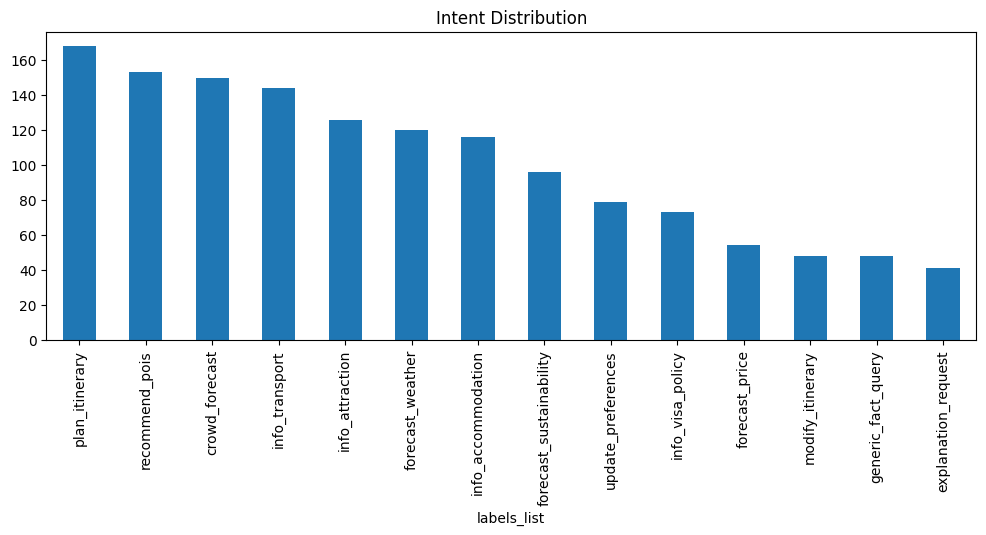

In [ ]:
import matplotlib.pyplot as plt

all_labels.value_counts().plot(kind='bar', figsize=(12,4))
plt.title("Intent Distribution")
plt.show()


In [ ]:
multi = df[df['labels'].str.contains(';')]
print(multi.head(10))
print("Number of multi-label rows:", len(multi))


      id                                               text          intent  \
168  201  Give me a few budget attractions close to Nuwa...  recommend_pois   
175  208  What are some romantic things to do near Colombo?  recommend_pois   
176  209  Give me a few nature attractions close to Mirissa  recommend_pois   
177  210  What are some quiet things to do near Nuwara E...  recommend_pois   
181  214  What are some eco friendly things to do near S...  recommend_pois   
182  215  Give me a few photography attractions close to...  recommend_pois   
183  216  Give me a few family friendly attractions clos...  recommend_pois   
184  218  What are some nature things to do near Trincom...  recommend_pois   
185  219  What are some budget things to do near Trincom...  recommend_pois   
189  223     Give me a few nature attractions close to Ella  recommend_pois   

     split                          labels  num_labels  \
168  train  info_attraction;recommend_pois           2   
175  train  in